# Project 1 – Pass-09


## Problem Definition



Business problem: Predict whether a customer will make a successfull transaction,

Data Science problem: This is a supervised learning and classification problem. I will use the Gaussian Naive Bayes model





## Data Collection

### Imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn import datasets, metrics, model_selection

### File Paths

In [ ]:
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.1-Transactions/Data/Transaction.train.big.csv'

### Load data

In [ ]:
#load data
transaction_df= pd.read_csv(
    url,
    usecols=range(50),
    nrows=50_000,
)

### Head

In [ ]:
# first few rows
transaction_df.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
0,0,train_0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,train_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,train_2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,3.4635,17.285,16.552,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
4,4,train_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Tail

In [ ]:
# last few rows
transaction_df.tail()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
49995,49995,train_49995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49996,49996,train_49996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49997,49997,train_49997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
49998,49998,train_49998,0.0,7.7807,11.4038,11.2746,NaN,7.6426,NaN,NaN,...,5.0832,18.0498,19.0913,NaN,-0.0056,NaN,NaN,NaN,NaN,NaN
49999,49999,train_49999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Shape

In [ ]:
# shape of data frame
transaction_df.shape

#output (# of rows, # of columns)

(50000, 50)

### Size

In [ ]:
# size of data frame
transaction_df.size

2500000

### Info

In [ ]:
# display meta-data
transaction_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 50 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  50000 non-null  int64  
 1   ID_code     50000 non-null  object 
 2   target      8506 non-null   float64
 3   var_0       8506 non-null   float64
 4   var_1       8506 non-null   float64
 5   var_2       8506 non-null   float64
 6   var_3       0 non-null      float64
 7   var_4       8506 non-null   float64
 8   var_5       0 non-null      float64
 9   var_6       0 non-null      float64
 10  var_7       8506 non-null   float64
 11  var_8       8506 non-null   float64
 12  var_9       0 non-null      float64
 13  var_10      0 non-null      float64
 14  var_11      0 non-null      float64
 15  var_12      0 non-null      float64
 16  var_13      0 non-null      float64
 17  var_14      8506 non-null   float64
 18  var_15      8506 non-null   float64
 19  var_16      0 non-null   

## Summary statistics

### Describe

In [ ]:
# display summary statistics
transaction_df.describe()


,Unnamed: 0,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
count,50000.000000,8506.000000,8506.000000,8506.000000,8506.000000,0.0,8506.000000,0.0,0.0,8506.000000,...,8506.000000,8506.000000,8506.000000,0.0,8506.000000,0.0,0.0,0.0,0.0,0.0
mean,24999.500000,0.098754,7.433406,15.873152,12.743673,NaN,-0.666477,NaN,NaN,1.216609,...,3.335911,19.317877,18.439225,NaN,5.768740,NaN,NaN,NaN,NaN,NaN
std,14433.901067,0.298349,2.998493,3.026206,4.167618,NaN,5.989788,NaN,NaN,5.206295,...,4.541526,5.013834,4.398037,NaN,7.462482,NaN,NaN,NaN,NaN,NaN
min,0.000000,0.000000,-0.482300,7.193400,1.263600,NaN,-20.962200,NaN,NaN,-12.739600,...,-13.999500,5.133100,6.673300,NaN,-15.121100,NaN,NaN,NaN,NaN,NaN
25%,12499.750000,0.000000,5.192575,13.822750,9.709300,NaN,-4.915275,NaN,NaN,-2.600700,...,0.018500,15.712475,15.044250,NaN,0.638225,NaN,NaN,NaN,NaN,NaN
50%,24999.500000,0.000000,7.286950,15.971650,12.660600,NaN,-0.585350,NaN,NaN,1.209900,...,3.366600,19.318800,18.293700,NaN,5.958900,NaN,NaN,NaN,NaN,NaN
75%,37499.250000,0.000000,9.523925,18.092725,15.755275,NaN,3.615725,NaN,NaN,5.146000,...,6.482825,22.906000,21.907575,NaN,11.427175,NaN,NaN,NaN,NaN,NaN
max,49999.000000,1.000000,16.716500,24.508500,25.848100,NaN,15.973100,NaN,NaN,18.419700,...,17.686100,33.940300,31.018900,NaN,26.401100,NaN,NaN,NaN,NaN,NaN


### Target value counts

NOTE: the ‘target’ column indicates a successful transaction (‘1’) or a no-transaction (‘0’). Verify these are the only values in that column, and that there are no nulls.

In [ ]:
# value_counts on target ; include nulls
transaction_df['target'].value_counts(dropna=False)

,count
target,
NaN,41494
0.0,7666
1.0,840


In [ ]:
#normalize value counts on target ; include nulls
transaction_df['target'].value_counts(normalize=True, dropna=False)

,proportion
target,
NaN,0.82988
0.0,0.15332
1.0,0.01680


### Nulls

In [ ]:
# look for nulls
transaction_df.isnull().sum().sort_values(ascending=False)



,0
var_6,50000
var_5,50000
var_11,50000
var_12,50000
var_3,50000
var_13,50000
var_9,50000
var_10,50000
var_42,50000
var_40,50000


In [ ]:
# look for nulls, display relative frequency
null_sum = transaction_df.isnull().sum()
null_freq = null_sum / transaction_df.shape[0] * 100
null_freq.sort_values()

#Output- target has 82% percent null values

,0
Unnamed: 0,0.000
ID_code,0.000
target,82.988
var_0,82.988
var_1,82.988
var_2,82.988
var_4,82.988
var_8,82.988
var_7,82.988
var_22,82.988


### Column data types

In [ ]:
# display data types
transaction_df.dtypes.sort_values()

,0
Unnamed: 0,int64
var_24,float64
var_25,float64
var_26,float64
var_27,float64
var_28,float64
var_29,float64
var_30,float64
var_31,float64
var_32,float64


### Unique elements

In [ ]:
# number of unique elements in every column (works on the whole dataframe)
transaction_df.nunique().sort_values(ascending=False)

,0
Unnamed: 0,50000
ID_code,50000
var_14,8362
var_41,8362
var_20,8347
var_7,8328
var_4,8320
var_37,8288
var_17,8286
var_38,8277


In [ ]:
# actual unique values in one column
transaction_df['target'].unique()

array([nan,  0.,  1.])

## Data Cleaning



Backup #1

In [ ]:
# backup copy of the original data
transaction_df_backup= transaction_df.copy()


In [ ]:
# restore from backup
transaction_df=transaction_df_backup.copy()

### Drop rows with no target
  - The target has 83% nulls. Model cant learn from rows with no answer, remove them first

Selected `target` for the target and drop the rows with null values

In [ ]:
# Keep only the rows where target is not missing
transaction_df_target=transaction_df.dropna(subset=['target']).copy()
transaction_df_target.head()

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
5,5,train_5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,...,0.7141,22.9317,16.5595,NaN,14.4219,NaN,NaN,NaN,NaN,NaN
11,11,train_11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,...,5.3051,12.4606,20.5618,NaN,-3.1316,NaN,NaN,NaN,NaN,NaN
15,15,train_15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,...,13.0779,9.9116,18.1721,NaN,18.0752,NaN,NaN,NaN,NaN,NaN
19,19,train_19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,...,9.0731,16.4656,16.4153,NaN,4.2070,NaN,NaN,NaN,NaN,NaN


In [ ]:
transaction_df_target.head(10) # this is to check

,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,...,var_37,var_38,var_39,var_40,var_41,var_42,var_43,var_44,var_45,var_46
3,3,train_3,0.0,4.6739,22.3915,15.6015,NaN,0.0464,NaN,NaN,...,3.4635,17.2850,16.5520,NaN,-6.8709,NaN,NaN,NaN,NaN,NaN
5,5,train_5,0.0,14.6962,18.3383,17.4788,NaN,-9.1355,NaN,NaN,...,0.7141,22.9317,16.5595,NaN,14.4219,NaN,NaN,NaN,NaN,NaN
11,11,train_11,0.0,4.4949,14.4142,13.2219,NaN,4.9140,NaN,NaN,...,5.3051,12.4606,20.5618,NaN,-3.1316,NaN,NaN,NaN,NaN,NaN
15,15,train_15,0.0,4.9657,16.2867,17.9579,NaN,0.6017,NaN,NaN,...,13.0779,9.9116,18.1721,NaN,18.0752,NaN,NaN,NaN,NaN,NaN
19,19,train_19,0.0,9.4287,18.7822,10.7630,NaN,-0.7532,NaN,NaN,...,9.0731,16.4656,16.4153,NaN,4.2070,NaN,NaN,NaN,NaN,NaN
22,22,train_22,0.0,6.7023,18.0127,18.4424,NaN,-5.1010,NaN,NaN,...,1.5274,22.9423,16.6135,NaN,-3.9533,NaN,NaN,NaN,NaN,NaN
29,29,train_29,0.0,11.2902,7.7553,6.6189,NaN,-7.0587,NaN,NaN,...,-1.4705,29.6371,20.2990,NaN,-3.2920,NaN,NaN,NaN,NaN,NaN
33,33,train_33,0.0,4.6761,14.6116,12.4063,NaN,-9.6457,NaN,NaN,...,0.7401,14.6928,23.1586,NaN,5.1716,NaN,NaN,NaN,NaN,NaN
35,35,train_35,0.0,10.5404,10.9793,11.0240,NaN,2.2579,NaN,NaN,...,4.6599,24.7852,12.2870,NaN,-4.8365,NaN,NaN,NaN,NaN,NaN
46,46,train_46,0.0,5.6315,13.2825,20.9955,NaN,3.1402,NaN,NaN,...,6.3786,27.2925,23.9322,NaN,4.6060,NaN,NaN,NaN,NaN,NaN


### Backup #2

In [ ]:
# make backup
transaction_df_target_backup = transaction_df_target.copy()

In [ ]:
# restore from back up
transaction_df_target = transaction_df_target_backup.copy()

### Address any rows with nulls

- If the number of nulls in a column is low, it would be easiest to drop the row.
- If the number of nulls in a column is high, it would be easiest to drop the column.
- If the number of nulls in a column is between the low and high, one should impute values for the nulls.

In [ ]:
transaction_df_target.isnull().sum().sort_values (ascending=False) # show me where the null value are

,0
var_6,8506
var_5,8506
var_11,8506
var_12,8506
var_3,8506
var_13,8506
var_9,8506
var_10,8506
var_42,8506
var_40,8506


In [ ]:
# Remove all the null row under target
transaction_df_target_clean =transaction_df_target.dropna(axis ='columns')
transaction_df_target_clean.isnull().sum().sort_values(ascending=False)

transaction_df_target_clean.head()



,Unnamed: 0,ID_code,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
3,3,train_3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,...,-0.3075,8.2199,19.4827,1.0175,5.0866,7.6264,3.4635,17.2850,16.5520,-6.8709
5,5,train_5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,...,-2.0043,8.8070,21.8550,2.2655,5.4675,4.4082,0.7141,22.9317,16.5595,14.4219
11,11,train_11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,...,0.5701,14.4752,17.0508,4.4676,0.7943,6.6745,5.3051,12.4606,20.5618,-3.1316
15,15,train_15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,...,1.8609,13.3220,10.5239,0.0104,4.2731,5.7718,13.0779,9.9116,18.1721,18.0752
19,19,train_19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,...,-5.8713,8.1795,9.1067,3.3064,1.7090,3.5648,9.0731,16.4656,16.4153,4.2070


In [ ]:
#DROP THE 'UNMAMED:0 and id_code, colums)
transaction_df_target_clean = transaction_df_target_clean.drop (columns=['Unnamed: 0','ID_code'])
transaction_df_target_clean

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
3,0.0,4.6739,22.3915,15.6015,0.0464,-1.9254,6.4760,21.6435,2.8817,11.6975,...,-0.3075,8.2199,19.4827,1.0175,5.0866,7.6264,3.4635,17.2850,16.5520,-6.8709
5,0.0,14.6962,18.3383,17.4788,-9.1355,-6.4882,6.0821,11.7476,2.2225,7.2218,...,-2.0043,8.8070,21.8550,2.2655,5.4675,4.4082,0.7141,22.9317,16.5595,14.4219
11,0.0,4.4949,14.4142,13.2219,4.9140,4.0501,5.8144,18.7136,3.4990,4.2892,...,0.5701,14.4752,17.0508,4.4676,0.7943,6.6745,5.3051,12.4606,20.5618,-3.1316
15,0.0,4.9657,16.2867,17.9579,0.6017,-5.4904,6.6670,8.1019,2.8910,8.2374,...,1.8609,13.3220,10.5239,0.0104,4.2731,5.7718,13.0779,9.9116,18.1721,18.0752
19,0.0,9.4287,18.7822,10.7630,-0.7532,8.8477,6.8045,19.0069,3.2771,12.6446,...,-5.8713,8.1795,9.1067,3.3064,1.7090,3.5648,9.0731,16.4656,16.4153,4.2070
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49986,0.0,4.3703,14.5321,12.5158,6.8990,4.8721,6.8599,3.6049,2.6936,3.3631,...,-1.7922,11.2487,13.0809,5.2903,3.4783,7.1363,9.6584,13.8385,15.1992,11.0333
49987,0.0,5.5247,19.5976,15.6233,10.3419,4.6616,6.6762,6.5438,2.9693,11.5063,...,1.9994,14.4838,22.3433,1.4035,9.0304,2.3784,1.4398,25.3678,16.4867,11.9542
49988,0.0,4.5371,19.5715,12.0498,0.0423,-2.0017,7.6199,12.3320,2.5670,4.1939,...,4.2031,10.1765,12.9907,3.1120,6.3440,4.1328,4.4885,24.3734,14.8631,5.6670
49994,0.0,6.0671,20.1542,14.4645,4.7347,-2.6682,6.9684,18.5923,2.9067,-0.8132,...,-6.8900,11.3503,11.2448,-0.1915,4.1460,4.0240,6.8356,16.5689,24.1643,5.1754


## Recommendations for Data Cleaning

**1. Identifier Columns**
- **Two columns:** `Unnamed: 0` is row numbers and `ID_code` is customer ID. cannot help predict anything
- **Recommendation:** Drop both columns. (I kept only `target` and `var_0` to `var_4`.)

**2. Null values:** No feature column have nulls. no action needed

**3. Target nulls:** 82% null values, rows with nulls are dropped

**4. Feature columns with high null counts:** None

**5. Medium null counts:** none

**6. Low null counts:** none

**7. Null rows:** none


## Exploratory Data Analysis ##

### Normal distribution of features:histogram

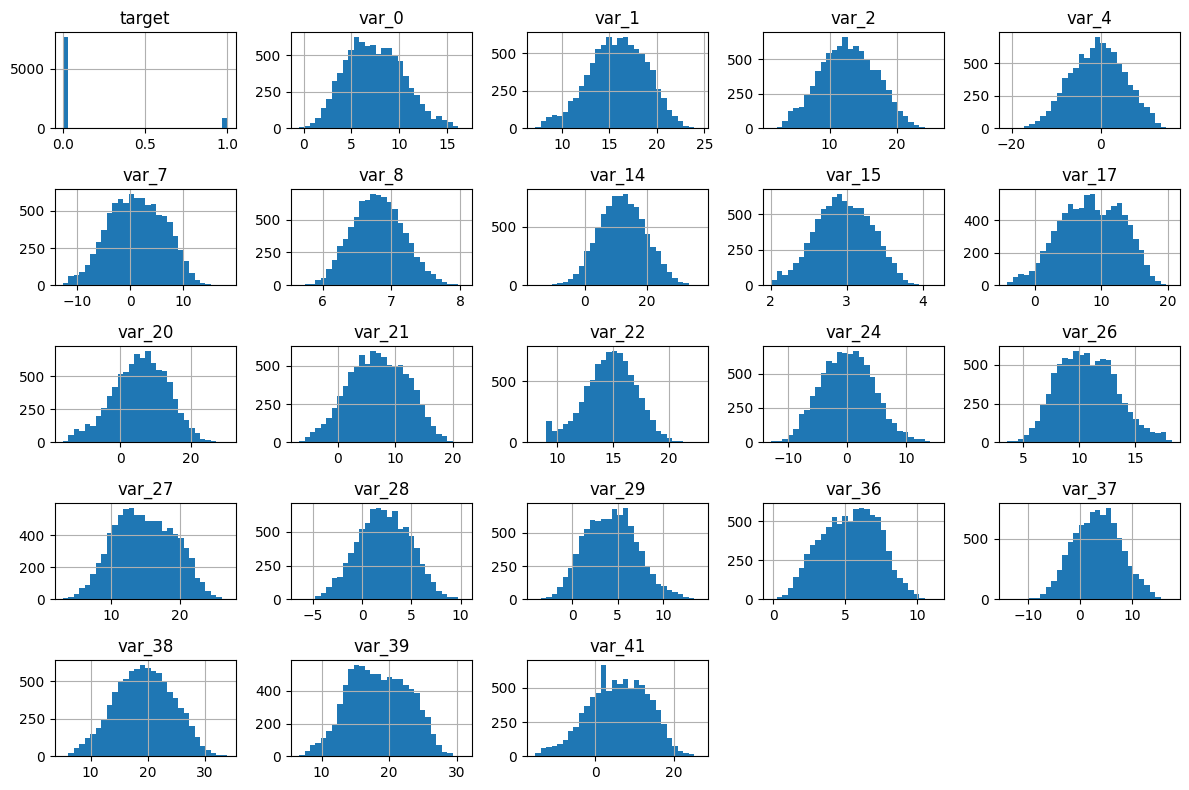

In [ ]:
# Display a histogram

transaction_df_target_clean.hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()


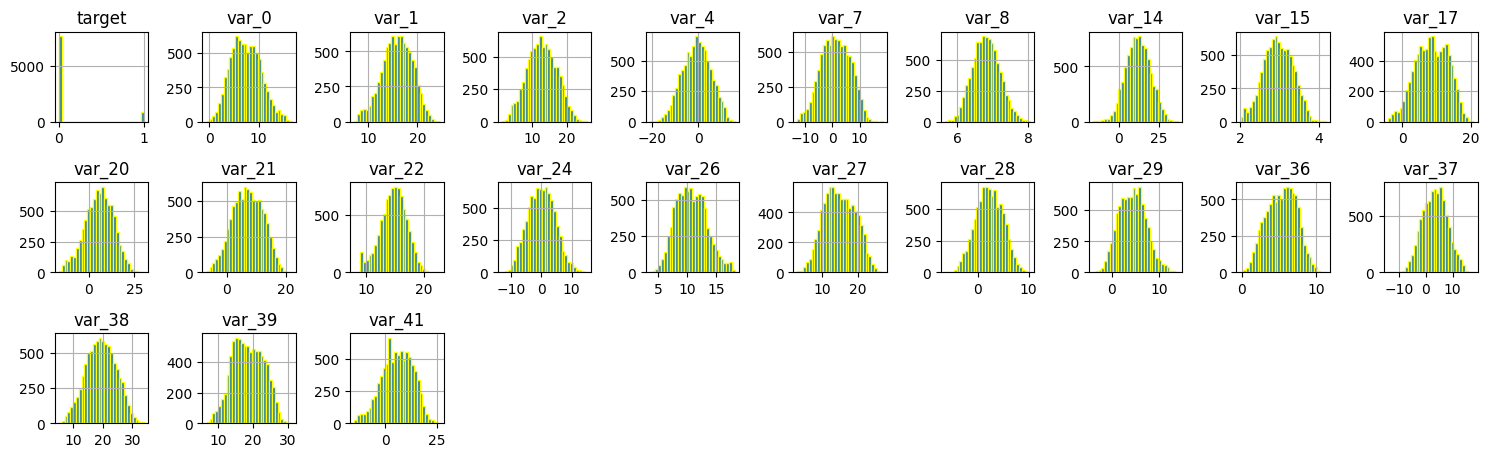

In [ ]:
# Check the distributions of the 20 features (var_0 to var_19)

transaction_df_target_clean.hist(
  figsize=(15,15), # size of the whole picture in inches(width,height)
  layout=(10,10),    # 5 rows, 4 column= 20 boxes
  bins=30,         # more bars, so the shape is clear
  edgecolor= "yellow"
)
plt.tight_layout()
plt.show()
#output- each graph look like a bell-shaped (first GNB assumption)

### Independence of features: Correlation matrix

In [ ]:
# Calculate a correlation matrix (target & features)
transaction_df_target_clean.corr()

,target,var_0,var_1,var_2,var_4,var_7,var_8,var_14,var_15,var_17,...,var_24,var_26,var_27,var_28,var_29,var_36,var_37,var_38,var_39,var_41
target,1.000000,0.050742,-0.039794,-0.060256,0.040229,-0.032706,0.048383,0.033708,-0.065024,-0.049189,...,0.045689,0.067268,-0.022421,-0.060705,0.049314,0.068738,0.041962,-0.057738,-0.038984,-0.059291
var_0,0.050742,1.000000,-0.001932,-0.002008,-0.004065,0.013920,0.005287,0.009787,0.003501,0.007570,...,0.007211,0.005079,-0.004578,0.001237,-0.010036,-0.008809,-0.000133,0.008856,0.007700,-0.004688
var_1,-0.039794,-0.001932,1.000000,-0.003072,0.019840,-0.010907,-0.010460,-0.013714,-0.001477,-0.002532,...,0.008056,-0.001995,-0.014325,0.003370,-0.010688,0.004288,-0.003056,-0.009136,0.008635,0.022035
var_2,-0.060256,-0.002008,-0.003072,1.000000,0.005686,-0.004277,0.004333,-0.005864,-0.003963,0.001795,...,0.007867,-0.002776,0.015401,0.003564,-0.004052,-0.018087,0.015591,-0.000161,0.011820,0.010744
var_4,0.040229,-0.004065,0.019840,0.005686,1.000000,-0.002771,-0.011529,0.002493,0.006865,-0.007378,...,0.017775,0.005338,0.005084,-0.013891,-0.001566,0.012709,-0.016146,-0.004427,-0.014136,0.001761
var_7,-0.032706,0.013920,-0.010907,-0.004277,-0.002771,1.000000,-0.017535,-0.016141,0.008960,0.007287,...,-0.008173,-0.001197,-0.011280,0.019048,-0.018282,-0.020851,-0.005682,-0.005131,-0.007425,-0.013643
var_8,0.048383,0.005287,-0.010460,0.004333,-0.011529,-0.017535,1.000000,-0.009329,0.006170,-0.006333,...,-0.003171,-0.011689,-0.001915,-0.005399,0.001543,0.007754,0.013471,-0.000151,0.010374,-0.019808
var_14,0.033708,0.009787,-0.013714,-0.005864,0.002493,-0.016141,-0.009329,1.000000,-0.002979,-0.002384,...,0.005116,-0.006524,-0.003718,-0.009721,-0.004758,0.021196,0.010578,0.005441,0.003580,-0.002742
var_15,-0.065024,0.003501,-0.001477,-0.003963,0.006865,0.008960,0.006170,-0.002979,1.000000,0.010272,...,0.006346,-0.025542,0.015068,0.004778,-0.000226,0.000304,0.013914,0.002860,0.012712,0.020895
var_17,-0.049189,0.007570,-0.002532,0.001795,-0.007378,0.007287,-0.006333,-0.002384,0.010272,1.000000,...,0.003891,-0.030515,-0.016135,-0.002544,0.003126,0.013883,-0.004958,0.022471,-0.004214,0.015237


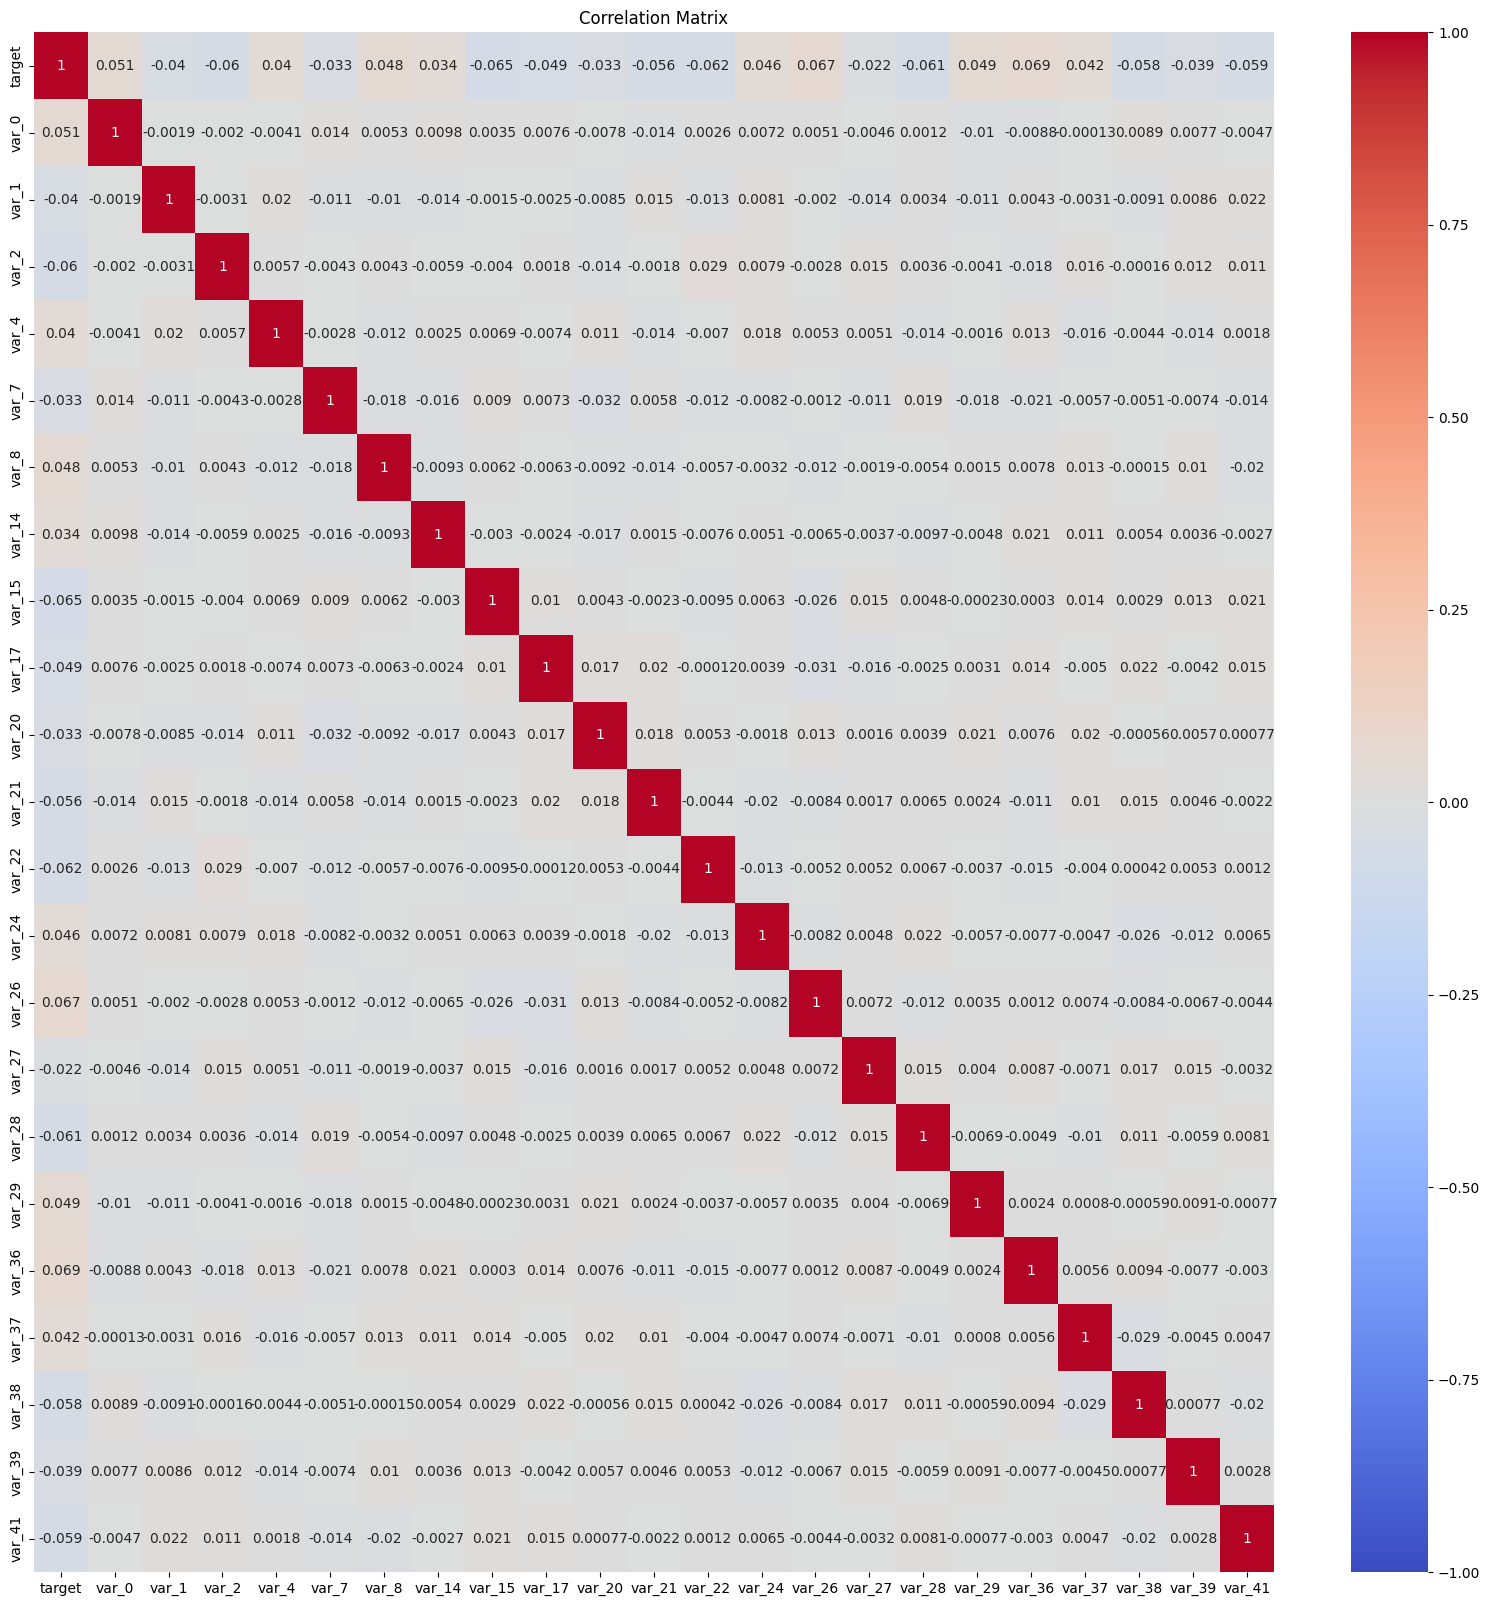

In [ ]:
# Display the correlation matrix

plt.figure(figsize=(20, 20))
sns.heatmap(transaction_df_target_clean.corr(),
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix')
plt.show()


In [ ]:
# select the features
feature_cols =[] #start with an empty list to hold the features
for col in transaction_df_target_clean.columns: #look at each column name
  if col.startswith ('var_'): #if the name start with 'var_, it's a feature
    feature_cols.append(col)

print(feature_cols)
print(len(feature_cols))

['var_0', 'var_1', 'var_2', 'var_4', 'var_7', 'var_8', 'var_14', 'var_15', 'var_17', 'var_20', 'var_21', 'var_22', 'var_24', 'var_26', 'var_27', 'var_28', 'var_29', 'var_36', 'var_37', 'var_38', 'var_39', 'var_41']
22


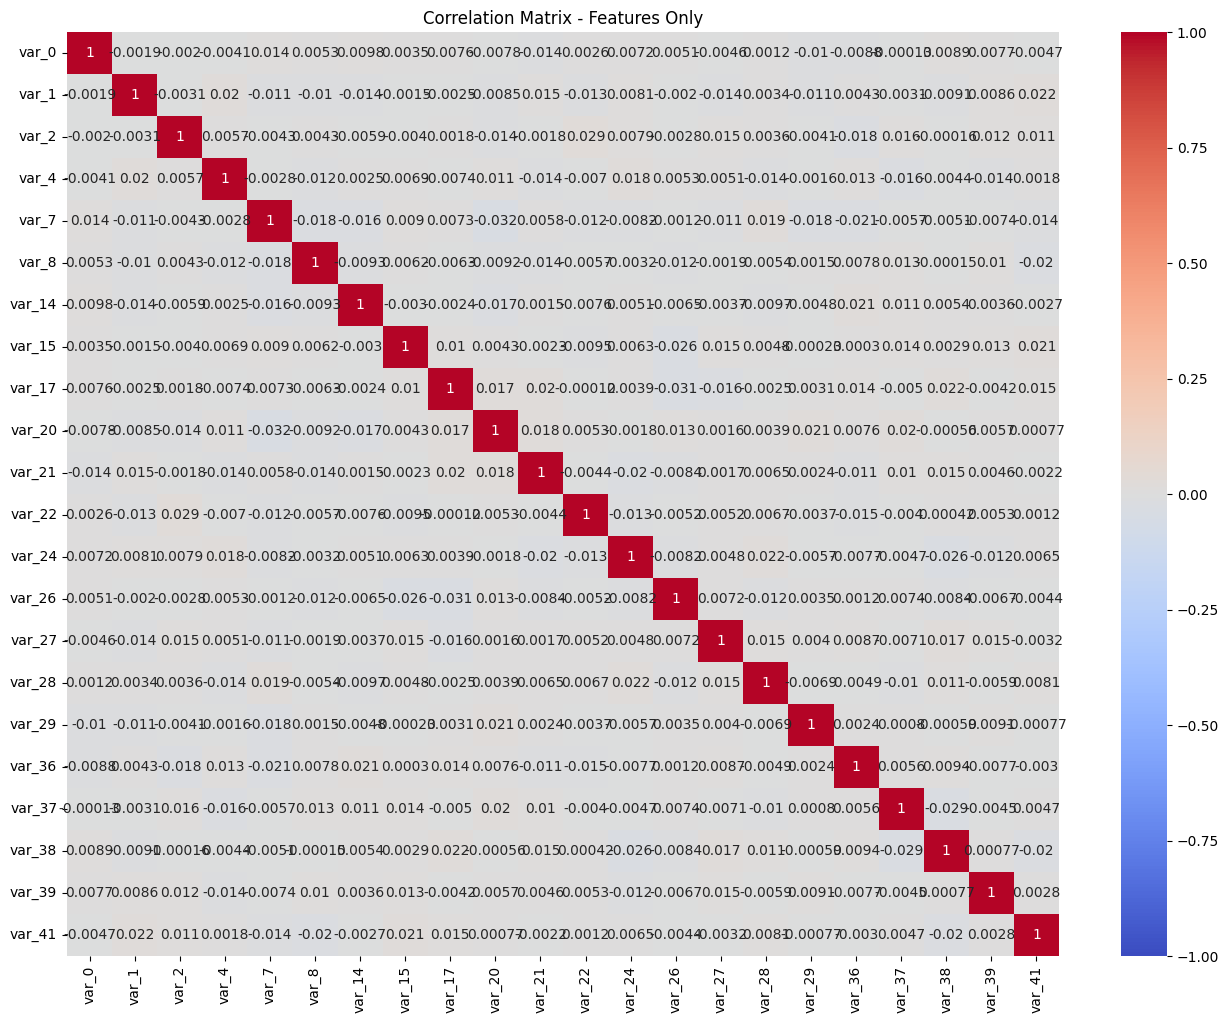

In [ ]:
# Calculate a correlation matrix (features only)
transaction_df_features_only = transaction_df_target_clean[feature_cols]
feature_corr = transaction_df_features_only.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(feature_corr,
            annot=True,
            cmap='coolwarm',  # blue = negative, red = positive
            center=0,         # white/gray = no correlation
            vmin=-1, vmax=1)  # full correlation range
plt.title('Correlation Matrix - Features Only')
plt.show()

#output- correlation between features are near 0
#look independent, 2nd GNB assumption


In [ ]:
# Create two data frames

# no transaction (target= 0)
transaction_df_no_success= transaction_df_target_clean[transaction_df_target_clean['target'] == 0].copy()

# successful transaction (target= 1)
transaction_df_successful= transaction_df_target_clean[transaction_df_target_clean['target'] == 1].copy()


print(type(transaction_df_successful))
print(type(transaction_df_no_success))

print(transaction_df_successful.shape)
print(transaction_df_no_success.shape)


<class 'pandas.core.frame.DataFrame'>
<class 'pandas.core.frame.DataFrame'>
(840, 23)
(7666, 23)


## Data Processing

### Single Cross-validation

In [ ]:
# Split data from into target and features
target =transaction_df_target_clean['target'].copy()
features= transaction_df_target_clean [feature_cols].copy()



In [ ]:
# Train test split
x_train, x_test, y_train, y_test = train_test_split( features, target, test_size=0.25, random_state=42)

In [ ]:
# verify shape of each data set from Train test split
for i in (x_train, x_test,y_train,y_test):
  print(i.shape)
  print(type(i))

(6379, 22)
<class 'pandas.core.frame.DataFrame'>
(2127, 22)
<class 'pandas.core.frame.DataFrame'>
(6379,)
<class 'pandas.core.series.Series'>
(2127,)
<class 'pandas.core.series.Series'>


### Model

In [ ]:
# Create an empty GNB model
modelGNB= GaussianNB()

### Fit

In [ ]:
# Train ( fit ) the model
modelGNB.fit(x_train,y_train)

GaussianNB()

### Prediction

In [ ]:
# Make prediction using the model
pred_result= modelGNB.predict(x_test)

### Performance

In [ ]:
# Calculate the accuracy
accuracy=metrics.accuracy_score(y_test,pred_result)
accuracy*100

90.03291020216267

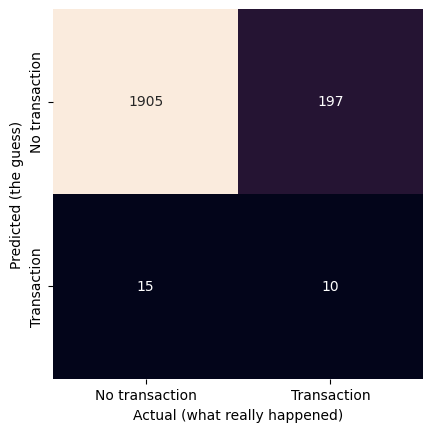

In [ ]:
# Display a confusion matrix
mat = metrics.confusion_matrix(y_test,pred_result)
names = ['No transaction', 'Transaction']
sns.heatmap(mat.T,
    square=True,
    annot=True,
    fmt='d',
    cbar=False,
    xticklabels=names,  #names start left to right
    yticklabels=names,  #names start from top to bottom
)

plt.xlabel('Actual (what really happened)')
plt.ylabel('Predicted (the guess)') ;

In [ ]:
#Classification report
print(metrics.classification_report(y_test, pred_result,zero_division=0 ))

#output show a warning message because model did not guess successful transactio
# zero_division=0 to remove the warning message


              precision    recall  f1-score   support

         0.0       0.91      0.99      0.95      1920
         1.0       0.40      0.05      0.09       207

    accuracy                           0.90      2127
   macro avg       0.65      0.52      0.52      2127
weighted avg       0.86      0.90      0.86      2127



### Communication of Results

The target show no transaction (‘0’) or  successful transaction (‘1’).

**Accuracy:** 90%


**Confusion matrix:**

 - 224: guessed no transaction, actually no transaction → right
  
 - 23: guessed no transaction, actually successfull transaction → wrong

 - 2: guessed sucessful transaction, actually no transaction -> wrong

 - 1: guess sucessful transaction, actually transaction ->right
  
**Classification report:**
  
  - Recall for successfull transaction: 0.04
    - The model found 1 out 24 successfull transaction.

  - Precision for successfull transaction: 0.33
    - The model said successfull transaction 3 times, right once  

  - 90% is just for the no transaction customer.

**Takeaway:** The model guessed "no transaction" for most customer transaction.

